# Applied Bayesian Data Analysis: Assignment 1 Study Guide

Author: [Kevin Thomas](mailto:ket189@pitt.edu)

## Imports

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.stats import binom
from scipy.stats import beta
from scipy.stats import poisson
from scipy.stats import gamma
from math import factorial
import scipy.integrate as integrate

## Bayes' Rule or Bayes' Theorem for Events (Point Estimates)

$$P(A \mid B) = \frac{P(B \mid A) P(A)}{P(B)}$$

* $P(A \mid B)$: The probability of event $A$ given that $B$ has occurred called the **posterior probability**.
* $P(B \mid A)$: The probability of event $B$ occurring given that $A$ has occurred called the **likelihood**.
* $P(A)$: The probability of event $A$ occurring called the **prior probability**.
* $P(B)$: The probability of event $B$ occurring called the **marginal probability** or **evidence**.

### Problem

Suppose a certain disease affects 1% of the population. There is a test for the disease:

* If you have the disease, the test is positive 99% of the time or **true positive**.
* If you do not have the disease, the test is positive 5% of the time or **false positive**.

### Question

If a randomly selected person tests positive, what is the probability that they actually have the disease?

### Define Events

* $A$: Person has the disease.
* $B$: Person tests positive.

### Given

* $P(A) = 0.01$: 1% have the disease.
* $P(B \mid A) = 0.99$: Test is positive if you have the disease.
* $P(B \mid \text{not} A) = 0.05$: Test is positive if you do not have the disease.
* $P(\text{not} A) = 0.99$: 99% do not have the disease.

### Step 1: Calculate $P(B)$ w/ Law of Total Probability

$P(B) = P(B \mid A)P(A) + P(B \mid \text{not} A) P(\text{not} A)$

$P(B) = (0.99 \times 0.01) + (0.05 \times 0.99)$

$P(B) = 0.0099 + 0.0495$

$P(B) = 0.0594$

### Step 2: Apply Bayes' Rule

$P(A \mid B) = \frac{P(B \mid A) P(A)}{P(B)}$

$P(A \mid B) = \frac{0.99 \times 0.01}{0.0594}$

$P(A \mid B) = \frac{0.0099}{0.0594}$

$P(A \mid B) \approx 0.1667$

### Answer

If a person tests positive, there is about a 16.7%, **posterior probability**, chance that they actually have the disease.

## Bayes' Rule or Bayes' Theorem for Distributions

$$\pi(\theta \mid \text{data}) = \frac{f(\text{data} \mid \theta)}{f(\text{data})} \pi(\theta)$$

* $\pi(\theta \mid \text{data})$: **Posterior probability distribution** for the quantity of interest $\theta$ after observing new evidence.
* $\pi(\theta)$: **Prior probability distribution** for $\theta$.
* $f(\text{data} \mid \theta)$: **Likelihood** of observing the data given $\theta$.
* $f(\text{data})$: **Marginal likelihood** or **evidence**; the total probability (for discrete) or density (for continuous) of observing your specific dataset, calculated as a sum or integral over all possible values of $\theta$ (i.e., $f(\text{data}) = \int f(\text{data} \mid \theta) \pi(\theta) d\theta$ for continuous, or $\sum f(\text{data} \mid \theta) \pi(\theta)$ for discrete).

### Challenges

* Mathematical complexity and computation: point estimates usually involve multiplication of numbers, while with distributions you may need to integrate functions that are not analytically tractable.
* Conceptual shift: distributions require thinking in terms of uncertainty across a range of outcomes, which can be less intuitive and demands a solid grasp of probability theory.

### Solution

* Many cases fall under [**conjugate priors**](https://en.wikipedia.org/wiki/Conjugate_prior#Table_of_conjugate_distributions) where the posterior distribution falls into the same family as the prior just with updated parameters. For example, the Beta distribution is conjugate to the Binomial and Bernoulli likelihoods, making Bayesian updating mathematically convenient.

### Normal Distribution

The normal distribution, also referred to as Gaussian, describes a random variable that its values are distributed symmetrically around its mean $\mu$. Values near the mean are more probable as compared to values further away. The normal distribution has 2 parameters associated with it, namely, the mean $\mu$ and the standard deviation $\sigma$. It is usually represented as $N(\mu, \sigma^2)$ and its mean (average), median (midpoint) and mode (most frequent observation) are equal. Many quantities are known (or assumed) to follow a normal distribution, such as a person’s height, a person’s IQ, the stock market return, etc.

In Bayesian inference, we often move from reasoning about point estimates (single values) to reasoning about entire distributions, which allows us to quantify uncertainty about parameters. For example, instead of just estimating the mean, we describe our uncertainty about the mean using a probability distribution.

For a normal distribution, 68.2% of the values will be within 1 standard deviation from the mean, 95.4% will fall within 2 standard deviations, and 99.7% within 3 standard deviations (as shown in the figure below). Data falling outside the range of 3 standard deviations are typically considered as rare occurrences.

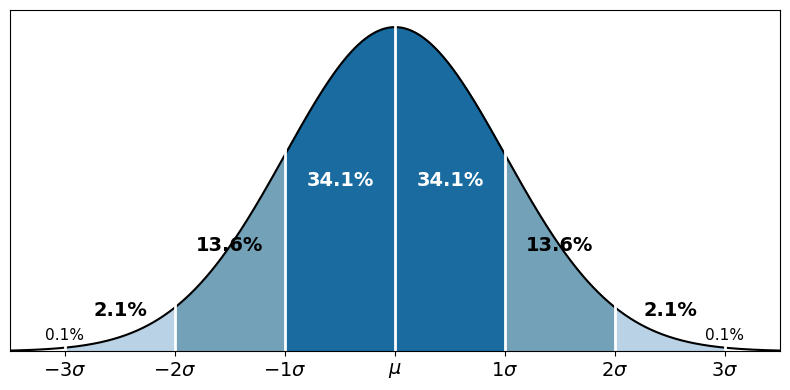

In [32]:
# Data for standard normal curve
mu, sigma = 0, 1
x = np.linspace(-4, 
                4, 
                1000)
y = norm.pdf(x, 
             mu, 
             sigma)

# Create figure and axis
fig, ax = plt.subplots(figsize=(8, 4))

# Plot normal curve
ax.plot(x, y, color='black')

# Shaded regions
regions = [(-3, -2), 
           (-2, -1), 
           (-1, 0), 
           (0, 1), 
           (1, 2), 
           (2, 3)]
colors = ['#b3cde3', 
          '#6497b1', 
          '#005b96', 
          '#005b96', 
          '#6497b1', 
          '#b3cde3']
percentages = ['2.1%', 
               '13.6%', 
               '34.1%', 
               '34.1%', 
               '13.6%', 
               '2.1%']
perc_x = [-2.5, 
          -1.5, 
          -0.5, 
          0.5, 
          1.5, 
          2.5]
perc_y = [0.05, 
          0.13, 
          0.21, 
          0.21, 
          0.13, 
          0.05]

# Fill regions and add percentage labels
for (left, right), color, pct, px, py in zip(regions, colors, percentages, perc_x, perc_y):
    x_fill = np.linspace(left, right, 500)
    ax.fill_between(x_fill, norm.pdf(x_fill, 
                                     mu, 
                                     sigma), 
                                     color=color, 
                                     alpha=0.9)
    ax.text(px, py, pct, ha='center', va='center', color='white' if abs(px) < 1 else 'black', fontsize=14, fontweight='bold')

# Extreme tails
ax.text(-3, 
        0.01, 
        '0.1%', 
        ha='center', 
        va='bottom', 
        fontsize=11)
ax.text(3, 
        0.01, 
        '0.1%', 
        ha='center', 
        va='bottom', 
        fontsize=11)

# Draw vertical lines
for pos in [-3, 
            -2, 
            -1, 
            0, 
            1, 
            2, 
            3]:
    ax.axvline(pos, 
               color='white', 
               lw=2)

# Set x-ticks and labels (single set)
ax.set_xticks([-3, 
               -2, 
               -1, 
               0, 
               1, 
               2, 
               3])
ax.set_xticklabels([r'$-3\sigma$', 
                    r'$-2\sigma$', 
                    r'$-1\sigma$', 
                    r'$\mu$', 
                    r'$1\sigma$', 
                    r'$2\sigma$', 
                    r'$3\sigma$'], 
                    fontsize=14)
ax.set_yticks([])

# Set limits and layout
ax.set_xlim(-3.5, 3.5)
ax.set_ylim(0, 0.42)
plt.tight_layout()

# Show plot
plt.show()

#### Standard Normal Distribution

This is a normal distribution with $\mu = 0$ and $\sigma = 1$. It is an important distribution because it can simplify the comparison between different normal distributions and provide convenience by providing a universal reference point. Every normal distribution can be standardized by subtracting its mean μ from the observations and dividing by its standard deviation $\sigma$.

This standardization provides us with the z-scores for these observations $z - score = x - \mu \sigma$. Z-scores have an average of 0 and a standard deviation of 1. A z-score of +/-2 indicates that an observation more extreme than that data point has at most a 5% chance of occurring. 

So overall, a normal distribution can be used to model continuous variables that are mostly centered around their mean and are symmetrical around it.

These percentages are rules of thumb for the standard normal; actual values depend on the exact distribution.

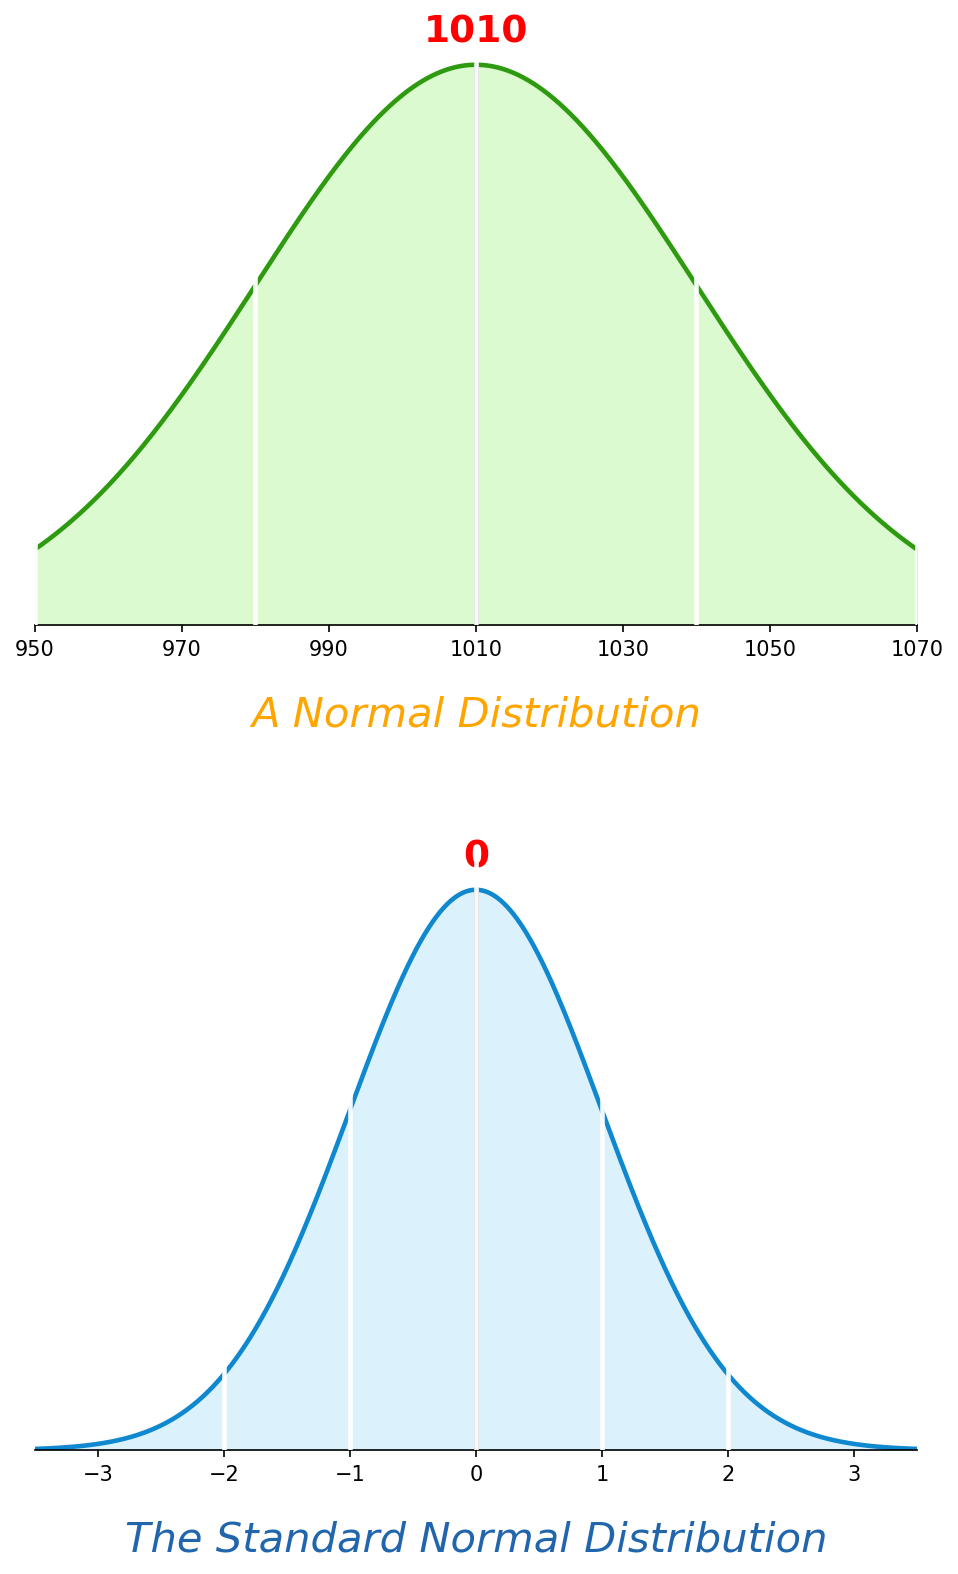

In [33]:
# Parameters
mu, sigma = 1010, 30
N = 2000  # dense sampling to avoid discretization differences

# Data: top uses same phi(z) as bottom (z = (x-mu)/sigma)
x_top = np.linspace(950, 
                    1070, 
                    N)
z_top = (x_top - mu) / sigma
y_top = norm.pdf(z_top, 
                 0, 
                 1)
x_bot = np.linspace(-3.5, 
                    3.5, 
                    N)
y_bot = norm.pdf(x_bot, 
                 0, 
                 1)

# Normalize to exact same peak (optional; shapes are identical without normalization
y_top = y_top / np.max(y_top)
y_bot = y_bot / np.max(y_bot)

# Figure
fig = plt.figure(figsize=(7, 11), dpi=150)
left, width = 0.08, 0.84
height = 0.36
top_bottom_gap = 0.06

# Place top and bottom axes with identical physical heights
ax_top = fig.add_axes([left, 
                       1 - top_bottom_gap - height, 
                       width, 
                       height])  # [left, bottom, width, height]
ax_bot = fig.add_axes([left, 
                       0.08, 
                       width, 
                       height])

# Common plotting style
lw = 2.2
alpha_fill = 0.55
antialiased = True

# --- Top: Normal (same phi) ---
ax_top.plot(x_top, 
            y_top, 
            color='#2e9a10', 
            lw=lw, 
            antialiased=antialiased)
ax_top.fill_between(x_top, 
                    0, 
                    y_top, 
                    color='#bff7a8', 
                    alpha=alpha_fill)

# white sigma lines mapped to x
for k in [-2, -1, 0, 1, 2]:
    ax_top.axvline(mu + k * sigma, 
                   color='white', 
                   lw=2.2, 
                   alpha=0.95, 
                   zorder=6)
ax_top.vlines(mu, 
              ymin=0, 
              ymax=1.0, 
              color='gray', 
              lw=2.2)
ax_top.text(mu, 
            1.04, 
            f'{mu}', 
            color='red', 
            ha='center', 
            fontsize=18, 
            fontweight='bold')
ax_top.set_xlim(950, 1070)
ax_top.set_xticks([950, 
                   970, 
                   990, 
                   1010, 
                   1030, 
                   1050, 
                   1070])
ax_top.set_yticks([])
for spine in ['top', 'right', 'left']:
    ax_top.spines[spine].set_visible(False)
ax_top.text(mu, -0.18, 
            'A Normal Distribution', 
            color='orange', 
            fontsize=20, 
            ha='center', 
            fontstyle='italic', 
            fontweight='medium', 
            clip_on=False)

# --- Bottom: Standard Normal ---
ax_bot.plot(x_bot, 
            y_bot, 
            color='#0f88d0', 
            lw=lw, 
            antialiased=antialiased)
ax_bot.fill_between(x_bot, 
                    0, 
                    y_bot, 
                    color='#bfe9fb', 
                    alpha=alpha_fill)
for k in [-2, -1, 0, 1, 2]:
    ax_bot.axvline(k, 
                   color='white', 
                   lw=2.2, 
                   alpha=0.95, 
                   zorder=6)
ax_bot.vlines(0, 
              ymin=0, 
              ymax=1.0, 
              color='gray', 
              lw=2.2)
ax_bot.text(0, 
            1.04, 
            '0', 
            color='red', 
            ha='center', 
            fontsize=18, 
            fontweight='bold')
ax_bot.set_xlim(-3.5, 3.5)
ax_bot.set_xticks([-3, 
                   -2,
                   -1, 
                   0, 
                   1,
                   2, 
                   3])
ax_bot.set_yticks([])
for spine in ['top', 
              'right', 
              'left']:
    ax_bot.spines[spine].set_visible(False)
ax_bot.text(0, 
            -0.18, 
            'The Standard Normal Distribution', 
            color='#2166ac', 
            fontsize=20, 
            ha='center', 
            fontstyle='italic', 
            fontweight='medium', 
            clip_on=False)

# Ensure identical vertical scales and identical visual height
ymax = 1.0
ax_top.set_ylim(0, ymax * 1.06)
ax_bot.set_ylim(0, ymax * 1.06)

# Show plot
plt.show()

### Binomial Distribution

The binomial distribution models a discrete random variable that represents the number of successes in a sequence of n independent binary (yes or no, success or failure) trials, each of which has a probability of success p. The parameters of a binomial distribution are n and p, and we refer to it as B(n , p). The following figures show the probability mass function for 3 binomial distributions with n = 20 and 3 different values of p. 

The binomial distribution can be used to model variables such as the number of made free throws from a player, the number of defective items in a batch of products, the number of patients responding positively to a new treatment, etc.  In general, for a variable to fit a binomial distribution must fit the following conditions: 

* Fixed number of trials n
* Only two outcomes per trial (0/1)
* Constant probability of success p across all trials
* Independence of trials

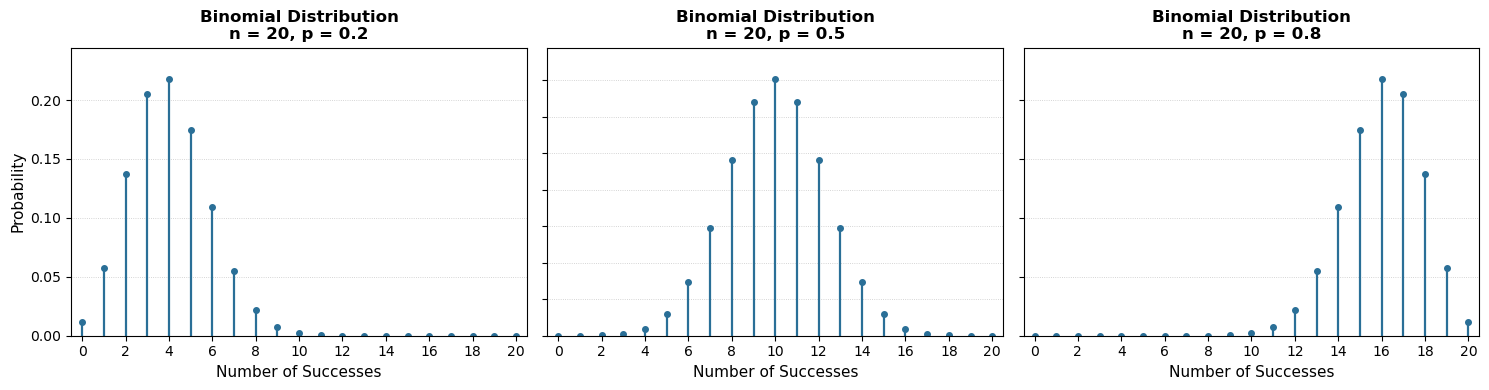

In [34]:
# Parameters
n = 20
ps = (0.2, 
      0.5, 
      0.8)
k = np.arange(n + 1)

# Create subplots: 1 row, 3 columns
fig, axes = plt.subplots(1, 
                         len(ps), 
                         figsize=(15, 4), 
                         sharey=False)

# Styling
line_color = "#2A6F97"
line_width = 1.6
marker_size = 4

# Plot each binomial distribution
for ax, p in zip(axes, ps):
    pmf = binom.pmf(k, 
                    n, 
                    p)

    # Vertical stems and markers
    ax.vlines(k, 
              0, 
              pmf, 
              color=line_color, 
              linewidth=line_width)
    ax.plot(k, 
            pmf, 
            'o', 
            color=line_color, 
            markersize=marker_size)

    # Title and labels
    ax.set_title(f'Binomial Distribution\nn = {n}, p = {p}', 
                 fontsize=12, 
                 fontweight='bold')
    ax.set_xlabel("Number of Successes", fontsize=11)
    ax.set_xlim(-0.5, n + 0.5)
    ax.set_ylim(0, pmf.max() * 1.12)
    ax.set_xticks(np.arange(0, 
                            n + 1, 
                            2))

    # Show y-axis label only on leftmost plot to mimic the reference layout
    if ax is axes[0]:
        ax.set_ylabel("Probability", fontsize=11)
    else:
        # hide tick labels but keep ticks for visual balance
        ax.set_yticklabels([])

    # Light horizontal gridlines
    ax.grid(axis='y', 
            linestyle=':', 
            linewidth=0.6, 
            alpha=0.7)

# Adjust layout
plt.tight_layout()

# Show plot
plt.show()

### Beta Distribution

In many practical applications, we will not know the true value of p, but we will use another distribution to model it. This distribution should be continuous and bounded between 0 and 1 since it models a probability. The Beta distribution is an appropriate one for this purpose and takes two shape parameters, $\alpha$ and $\beta$ (both positive).  The following graph shows 3 different Beta distributions that are obtained for different values of $\alpha$ and $\beta$.

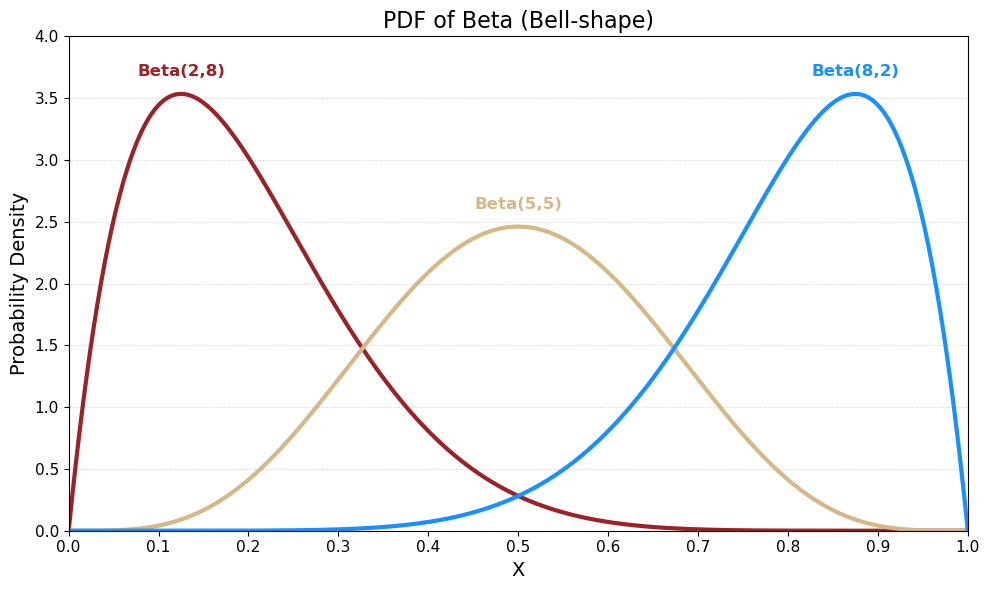

In [35]:
# X axis
x = np.linspace(0, 
                1, 
                1000)

# Beta parameters and styling (order: left, center, right)
params = [(2, 8), 
          (5, 5), 
          (8, 2)]
labels = ['Beta(2,8)', 
          'Beta(5,5)', 
          'Beta(8,2)']
colors = ['#9b2226', 
          '#d6b887', 
          '#1890ff']   # maroon, tan, bright blue

# Create figure
fig, ax = plt.subplots(figsize=(10, 6))

# Plot each beta PDF
lines = []
for (a, b), lbl, c in zip(params, labels, colors):
    y = beta.pdf(x, 
                 a, 
                 b)
    ln, = ax.plot(x, 
                  y, 
                  color=c, 
                  lw=3)
    lines.append(ln)

    # place a label near the mode (if a,b > 1 the mode is (a-1)/(a+b-2))
    if a > 1 and b > 1:
        mode_x = (a - 1) / (a + b - 2)
    else:
        # if one of parameters <= 1, the mode is at the boundary; put label near a small offset
        mode_x = 0.05 if a <= 1 else 0.95
    mode_y = beta.pdf(mode_x, a, b)
    # offset the text slightly upward for clarity
    ax.text(mode_x, 
            mode_y + 0.12, 
            lbl, 
            color=c, 
            fontsize=12, 
            fontweight='bold',
            ha='center', 
            va='bottom')

# Title and labels
ax.set_title('PDF of Beta (Bell-shape)', fontsize=16)
ax.set_xlabel('X', fontsize=14)
ax.set_ylabel('Probability Density', fontsize=14)

# Limits and ticks (match the reference look)
ax.set_xlim(0, 1)
ax.set_ylim(0, 4.0)
ax.set_xticks(np.linspace(0, 
                          1, 
                          11))
ax.tick_params(axis='both', 
               which='major', 
               labelsize=11)

# Light grid and nicer layout
ax.grid(axis='y', 
        linestyle=':', 
        linewidth=0.7, 
        alpha=0.6)
plt.tight_layout()

# Show plot
plt.show()

### Poisson Distribution

The Poisson distribution is another discrete probability distribution that models the number of events that happen within a fixed interval of time. These events happen independently of the time of the last event, and they have a known constant rate $\lambda$. This rate $\lambda$ is the only parameter of the distribution, and it is also the mean and the variance of the distribution. The Poisson distribution also belongs to the exponential family, and hence its shape for different values of $\lambda$ looks like the following: 

The Poisson distribution is appropriate for modeling the number of customer arrivals at a store in an hour, the number of potholes in a km of road, the number of earthquakes in a region per year, etc. In general, the Poisson distribution is appropriate when the following assumptions are satisfied: 

* Events occur independently
* The average rate of occurrence is constant over the interval
* Two events cannot occur at exactly the same instance

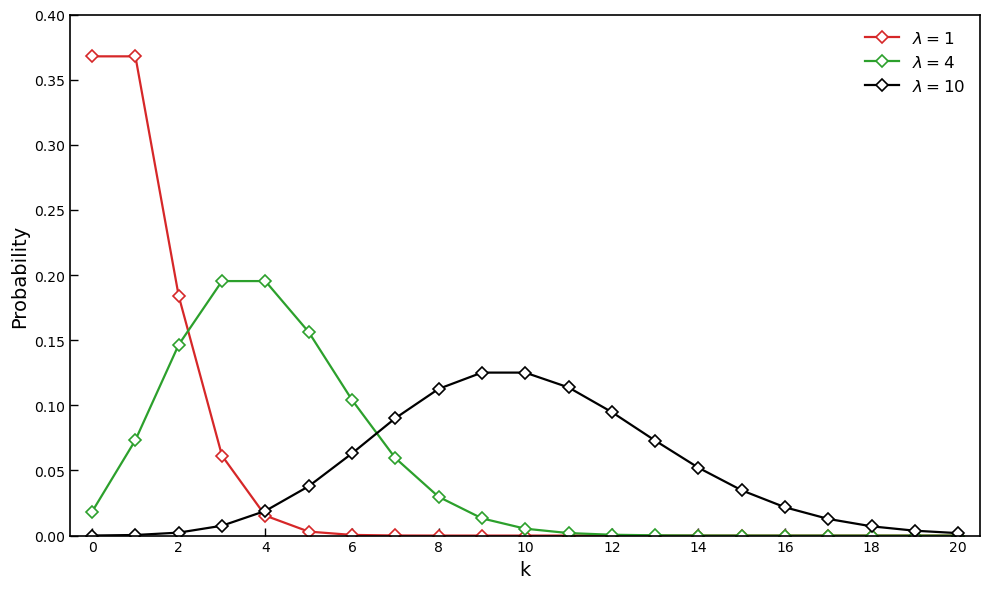

In [36]:
# Parameters
ks = np.arange(0, 21)
lambdas = [1, 4, 10]
colors = ['#d62728',
          '#2ca02c', 
          '#000000']  # red, green, black
markers = ['D', 
           'D', 
           'D']  # diamond markers for all

# Create figure
fig, ax = plt.subplots(figsize=(10, 6))

# Plot each Poisson PMF
for lam, c, m in zip(lambdas, colors, markers):
    pmf = poisson.pmf(ks, lam)
    # line with diamond markers, marker facecolor none to mimic outlined diamonds
    ax.plot(ks, 
            pmf, 
            color=c, 
            lw=1.6, 
            marker=m, 
            ms=6, 
            mec=c, 
            mfc='white', 
            mew=1.2, 
            label=fr'$\lambda={lam}$')

# Styling to resemble the reference appearance (inward ticks, bold frame ticks)
ax.set_xlim(-0.5, 20.5)
ax.set_ylim(0, 0.40)
ax.set_xlabel('k', fontsize=14)
ax.set_ylabel('Probability', fontsize=14)

# Ticks inwards like the reference figure
ax.tick_params(axis='both',
               which='major', 
               direction='in', 
               length=6, 
               width=1)
ax.tick_params(axis='both', 
               which='minor', 
               direction='in', 
               length=3, 
               width=0.8)
ax.xaxis.set_ticks(np.arange(0, 
                             21, 
                             2))
ax.yaxis.set_ticks(np.linspace(0, 
                               0.4, 
                               9))

# Make all spines a bit thicker to match the look
for spine in ax.spines.values():
    spine.set_linewidth(1.2)

# Legend placed near the top-right, styled
leg = ax.legend(loc='upper right', 
                frameon=False, 
                fontsize=12)
leg.get_frame()
plt.tight_layout()

# Show plot
plt.show()

### Problem

Your team has brought in a kicker for evaluation. 

* The special teams coach has a player attempt 20 50-yard field goals and he makes 16 of them.


### Question

What is his true success rate $\sigma$ on 50-yard field goals? Is he an 80% kicker on 50-yard field goals? 

### Define Events

* Before having the kicker attempt any field goals, we have a prior belief on his ability.
* This could be the average success rate of the NFL kickers collectively on 50-yard field goals.
* The average success rate is ~70%. For a Beta($\alpha=5$, $\beta=2$) prior, the mean is $\alpha/(\alpha+\beta) = 5/7 \approx 0.714$, which closely matches this average.
  - Some kickers are exceptional and above average.
  - Some kickers are bad at long field goals.
  - Most of the kickers are average.

### Distribution

We will use a **Beta distribution** which is a flexible way to describe beliefs about probability. It is defined on the closed space between 0 - 1 which is ideal for modeling success rate.

The parameters for the Beta distribution will reflect the fact that it is centered around 70% w/ some reasonable spread based on what we know about kickers performance.

### Bayes Theorem and Conjugate Priors

$$f_{Beta}(\sigma; \alpha, \beta) = \frac{1}{B(\alpha, \beta)} \sigma^{\alpha-1} (1 - \sigma)^{\beta-1},$$

$$B(\alpha, \beta) = \frac{(\alpha-1)! (\beta-1)!}{(\alpha + \beta - 1)!},$$

$$0 \leq \sigma \leq 1$$

$$\alpha = 5,\ \beta = 2$$

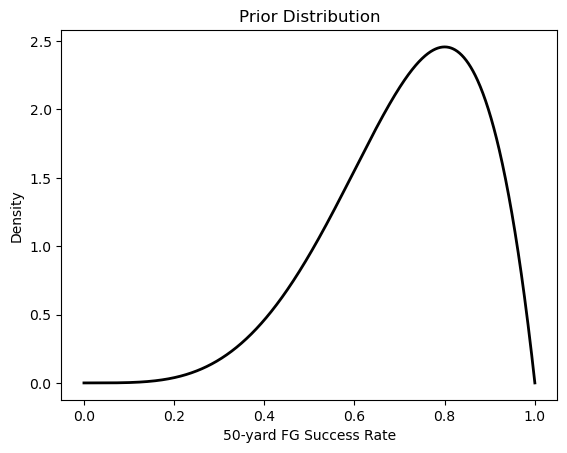

In [37]:
# Create a figure and axis
fig, ax = plt.subplots(1, 1)

# (i) define the prior
rv = beta(a=5, b=2)  # mean=70; alpha=5, beta=2
prior = lambda x: rv.pdf(x)

# (ii) plot the prior distribution over x
ax.plot(x, prior(x), 'k-', lw=2)
plt.xlabel('50-yard FG Success Rate')
plt.ylabel('Density')
plt.title('Prior Distribution')
plt.show()

Next we need to calculate the likelihood of observing the data we have observed given the success rate $\sigma$ (we make our calculations as if we know its value, but really this is the parameter we want to estimate).

For this example, the likelihood is a **Binomial distribution** with the probability of success $\sigma$.

We will use a **Binomial likelihood** to estimate 16 successes on 20 tries.

### Step 1: Calculate w/ Law of Total Probability

We can now obtain the total probability by normalizing so the integral is equal to 1 therefore integrating over all the possible values of $\sigma$.

#### Likelihood

$$
f("16 - of - 20" \mid \sigma) = \binom{20}{16} \sigma^{16} (1 - \sigma)^4
$$

#### Marginal Likelihood (Law of Total Probability, w/ Beta prior parameters $\alpha = 1$, $\beta = 1$ for the **uniform prior**)

$$
f("16 - of - 20") = \int_{0}^{1} \binom{20}{16} \sigma^{16}(1 - \sigma)^{4} \frac{1}{B(\alpha, \beta)} \sigma^{\alpha-1}(1-\sigma)^{\beta-1} d\sigma
$$

* This marginal likelihood is the denominator in Bayes' rule and ensures the posterior is a valid probability distribution (i.e., integrates to 1).

### Step 2: Apply Bayes' Rule

Using Bayes's rule, we can now obtain the posterior distribution where the probability of the kicker is at least 80% integrating 0.8 to 1.


$$
\Pr[\textit{kicker } \sigma \geq 80\%] = \int_{0.8}^{1} \pi(\sigma \mid "16\text{-}of\text{-}20") d\sigma
$$

$$
\Pr[\textit{kicker } \sigma \geq 80\%] = 0.42
$$

In [38]:
def update_posterior_beta(prior, 
                          x2, 
                          x1):
    """
    Update a prior pdf with a Binomial likelihood (including binomial coefficient) for observed successes
    and return the normalized posterior pdf function.

    Parameters
    ----------
    prior : callable
        Prior probability density function p(p), where 0 <= p <= 1.
    x2 : int
        Number of observed successes.
    x1 : int
        Number of trials.

    Returns
    -------
    callable
        Posterior pdf function p(p | data), normalized over (0, 1).
    """
    # Binomial coefficient
    c = factorial(x1) / (factorial(x2) * factorial(x1 - x2))

    # Likelihood function
    l = lambda x: c * (x ** x2) * ((1 - x) ** (x1 - x2))

    # Unnormalized posterior function
    f = lambda x: prior(x) * l(x)

    # Normalization constant
    tp = integrate.quad(f, 0, 1)[0]

    # Normalized posterior function
    post = lambda x: f(x) / tp

    # Return the posterior function
    return post


# Example usage
post = update_posterior_beta(prior, 16, 20)
prob = integrate.quad(post, float(0.8), float(1))[0]
prob

0.42251360872607807

### Answer

This value represents $\Pr[\sigma \geq 0.8 \mid \text{data}]$, i.e., the probability (given our prior and the observed 16/20 makes) that the kicker is truly an 80% or better kicker from 50 yards. If the probability is approximately 0.42, then there is a 42% chance the kicker is at least 80% accurate, given the data and prior assumptions.

## Conjugate Priors

| **Likelihood**   | **Prior**    | **Discrete/Continuous**               | **Usage Example**                                                                                                                                             |
|:-----------------|:-------------|:--------------------------------------|:--------------------------------------------------------------------------------------------------------------------------------------------------------------|
| Bernoulli        | Beta         | Discrete (outcome), Continuous (θ)    | *Coin Flips:*<br>Prior: $\mathrm{Beta}(1,1)$<br>Data: HHTTH<br>Posterior: $\mathrm{Beta}(3,3)$                                                                 |
| Binomial         | Beta         | Discrete (successes in $n$ trials), Continuous (θ) | *Batch Successes:*<br>Prior: $\mathrm{Beta}(2,2)$<br>Data: 7 successes in 10 trials<br>Posterior: $\mathrm{Beta}(9,5)$  |
| Poisson          | Gamma        | Discrete (counts), Continuous (rate)  | *Emails/Hour:*<br>Prior: $\mathrm{Gamma}(2,2)$<br>Data: 3, 2, 0<br>Posterior: $\mathrm{Gamma}(7,5)$                                                           |
| Multinomial      | Dirichlet    | Discrete (categories), Continuous (probabilities) | *Die Rolls:*<br>Prior: $\mathrm{Dirichlet}(1,1,1,1,1,1)$<br>Data: [2,1,0,0,1,2]<br>Posterior: $\mathrm{Dirichlet}(3,2,1,1,2,3)$                      |
| Normal           | Normal       | Continuous                            | *Heights (unknown mean):*<br>Prior: $\mathcal{N}(170, 10^2)$<br>Data: 172, 168<br>Posterior: $\mathcal{N}(170, 5^2)$                                         |
| Uniform          | Pareto       | Continuous                            | *Minimum Value Modeling:*<br>Prior: $\mathrm{Pareto}(x_m=1,\ \alpha=2)$<br>Data: $\geq 5$<br>Posterior: $\mathrm{Pareto}(x_m=5,\ \alpha=3)$                  |
| Exponential      | Gamma        | Continuous                            | *Time Between Events:*<br>Prior: $\mathrm{Gamma}(1,1)$<br>Data: 2, 3, 1<br>Posterior: $\mathrm{Gamma}(4,7)$                                                   |

## Poisson Likelihood

### Bayesian Inference for Poisson Rate with Gamma Prior

Let's estimate the number $Y$ of e-mails the HR department receives per hour, assuming $Y$ follows a Poisson distribution with unknown rate $\lambda$, where $\lambda$ is the constant rate parameter that we are looking to estimate. We have observed $Y = [3, 4, 2, 5, 3]$ e-mails each hour respectively.

Since the observations are independent, the likelihood of observing these data points is just the product of the likelihood of observing each of the data points individually.

$$
L(\lambda) = \Pr[Y \mid \lambda] = \prod_{i=1}^{5} \frac{\lambda^{y_i} e^{-\lambda}}{y_i!}
= \frac{\lambda^3 e^{-\lambda}}{3!} \cdot \frac{\lambda^4 e^{-\lambda}}{4!} \cdot \frac{\lambda^2 e^{-\lambda}}{2!} \cdot \frac{\lambda^5 e^{-\lambda}}{5!} \cdot \frac{\lambda^3 e^{-\lambda}}{3!}
$$

Combining the different terms, we get:

$$
L(\lambda) \sim \lambda^{17} \cdot e^{-5\lambda}
$$

Next, we need to put some prior on the unknown value of the rate $\lambda$. The conjugate prior for the Poisson likelihood is the Gamma distribution, which is parametrized by two parameters, shape $\alpha$ and rate $\beta$. The Gamma distribution has a mean of $\alpha \div \beta$ and a variance of $\alpha \div \beta^2$. So if we consider our prior belief being that the HR department is expected to get 3 emails per hour, we can select $\alpha = 3$ and $\beta = 1$, which will give a mean of 3 and a variance of 3 as well.

The posterior distribution for $\lambda$ is proportional to the product of the prior with the likelihood, i.e.,
$$
P[\lambda \mid y] \propto P[\lambda \mid \alpha, \beta] \cdot L(\lambda)
$$

Substituting from above, we get:
$$
P[\lambda \mid y] \propto \lambda^{19} \cdot e^{-6\lambda}
$$

We can find the normalization constant $C$ of this posterior by integrating over all possible values of $\lambda$ and equating it to 1:
$$
\int_{0}^{\infty} C \cdot \lambda^{19} \cdot e^{-6\lambda} \, d\lambda = 1
$$

This will give us the proper (normalized) posterior that we can use.

### Model
- **Likelihood:**
  $$
  \Pr[Y = y \mid \lambda] = \frac{\lambda^y e^{-\lambda}}{y!}
  $$
- **Joint Likelihood:**
  $$
  L(\lambda) = \prod_{i=1}^5 \frac{\lambda^{y_i} e^{-\lambda}}{y_i!} \propto \lambda^{17} e^{-5\lambda}
  $$
- **Prior:** Gamma($\alpha=3$, $\beta=1$) (mean 3, variance 3)
  $$
  p(\lambda) = \frac{\beta^\alpha}{\Gamma(\alpha)} \lambda^{\alpha-1} e^{-\beta \lambda}
  $$
- **Posterior:**
  $$
  p(\lambda \mid y) \propto \lambda^{19} e^{-6\lambda}
  $$

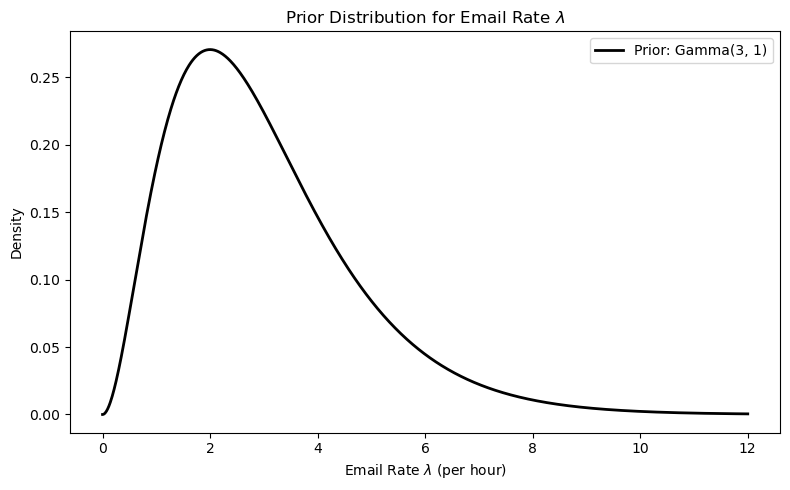

In [39]:
# Observed data: emails per hour
y = np.array([3, 
              4, 
              2, 
              5, 
              3])
n = len(y)
sum_y = np.sum(y)

# Prior parameters (Gamma prior: shape=alpha, rate=beta)
alpha_prior = 3
beta_prior = 1

# Posterior parameters (conjugate update for Poisson likelihood and Gamma prior)
alpha_post = alpha_prior + sum_y
beta_post = beta_prior + n

# Plotting range for lambda
lmbda = np.linspace(0, 
                    12, 
                    1000)

# Prior and posterior distributions
prior_pdf = gamma.pdf(lmbda, 
                      a=alpha_prior, 
                      scale=1/beta_prior)

# Plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(lmbda, 
        prior_pdf, 
        label=f'Prior: Gamma({alpha_prior}, {beta_prior})', 
        color='black', 
        lw=2)
ax.set_xlabel(r'Email Rate $\lambda$ (per hour)')
ax.set_ylabel('Density')
ax.set_title(r'Prior Distribution for Email Rate $\lambda$')
ax.legend()
plt.tight_layout()
plt.show()

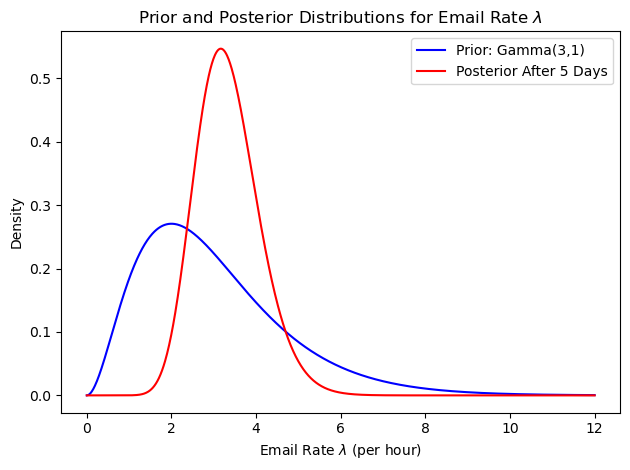

In [40]:
# Observed counts: emails per hour for 5 days (HR example)
obs = [3, 
       4, 
       2, 
       5, 
       3]

# Define the initial prior: Gamma(3, 1)
prior_rv = gamma(a=3, scale=1/1)
prior = lambda lam: prior_rv.pdf(lam)


# Update belief based on observations
def update_posterior(prior_func, observation):
    """
    Update a prior pdf with a Poisson likelihood for one observed count and
    return the normalized posterior pdf function.

    Parameters
    ----------
    prior_func : callable
        Prior probability density function p(lambda).
    observation : int
        Observed number of events (Poisson count) used to form the likelihood.

    Returns
    -------
    callable
        Posterior pdf function p(lambda | observation), normalized over (0, inf).
    """
    # Define the Poisson likelihood function for the observed count
    l = lambda lam: (lam ** observation * np.exp(-lam)) / factorial(observation)

    # Multiply the prior by the likelihood to get the unnormalized posterior
    f = lambda lam: prior_func(lam) * l(lam)

    #  Integrate the unnormalized posterior over all possible lambda values to normalize it
    tp = integrate.quad(f, 
                        0, 
                        np.inf)[0]

    # Define the normalized posterior function (posterior PDF)
    post = lambda lam: f(lam) / tp

    # Return the normalized posterior function
    return post


# Plot the posteriors
x = np.linspace(0, 
                12, 
                1000)
fig, ax = plt.subplots(1, 1)

# Sequentially update posteriors and initialize the list of posterior functions with the prior as the first element
posteriors = [prior]

# Loop over each observed count in obs
for ob in obs:
    # Update the posterior using the latest observation and previous posterior
    new_post = update_posterior(posteriors[-1], ob)

    # Append the new posterior to the list of posteriors
    posteriors.append(new_post)

# Plot the original prior (before updates)
ax.plot(x, [prior(xi) for xi in x], label='Prior: Gamma(3,1)', color='blue')

# Plot the final posterior (after all updates)
ax.plot(x, [posteriors[-1](xi) for xi in x], label='Posterior After 5 Days', color='red')
ax.legend()
plt.xlabel(r'Email Rate $\lambda$ (per hour)')
plt.ylabel('Density')
plt.title(r'Prior and Posterior Distributions for Email Rate $\lambda$')
plt.tight_layout()
plt.show()

In [41]:
def integrate_posterior(a, 
                        b, 
                        prior, 
                        obs):
    """
    Compute the probability that lambda lies in [a, b] under the posterior
    obtained by sequentially updating `prior` with observations in `obs`.

    Parameters
    ----------
    a : float
        Lower bound of the integration interval.
    b : float
        Upper bound of the integration interval.
    prior : callable
        Prior probability density function p(lambda).
    obs : iterable of int
        Sequence of observed Poisson counts used to update the posterior
        sequentially (each observation is passed to update_posterior).

    Returns
    -------
    float
        The value of the integral ∫_a^b p(lambda | data) d(lambda), where the
        posterior is the result of applying update_posterior for each observation.
    """
    # Start with the initial prior as the current belief about lambda
    current = prior

    # Sequentially update the posterior with each observation in obs
    for ob in obs:
        current = update_posterior(current, ob)

    # Integrate the final posterior over the interval [a, b] to get the probability
    return integrate.quad(current, a, b)[0]


# Suppose prior and obs are already defined for the HR example:
prob = integrate_posterior(4, 6, prior, obs)
print(f'Probability that λ is between 4 and 6: {prob:.3f}')

Probability that λ is between 4 and 6: 0.179


In [42]:
def credible_interval_posterior(posterior, 
                                lower, 
                                upper):
    """
    Compute an equal-tailed credible interval from a posterior pdf function using a grid-based CDF.

    Parameters
    ----------
    posterior : callable
        Posterior probability density function p(lambda). Should accept a scalar and return density.
    lower : float
        Lower tail cumulative probability (e.g., 0.025 for a 95% equal-tailed CI).
    upper : float
        Upper tail cumulative probability (e.g., 0.975 for a 95% equal-tailed CI).
    
    Returns
    -------
    tuple (float, float)
        (lower_bound, upper_bound) values of the parameter corresponding to the requested
        cumulative probabilities. Computation is done on a dense grid (default 10000 points).
    """
    # Create a dense grid of lambda values from 0 to 12 (sufficient for HR example)
    x_vals = np.linspace(0, 12, 10000)

    # Compute the spacing between grid points (needed for numerical integration)
    dx = x_vals[1] - x_vals[0]

    # Evaluate the posterior PDF at each point in the grid
    pdf_vals = np.array([posterior(xi) for xi in x_vals])

    # Compute the cumulative distribution function (CDF) by summing the PDF values and multiplying by dx
    cdf_vals = np.cumsum(pdf_vals) * dx

    # Find the lambda value where the CDF first reaches the lower cumulative probability
    lower_bound = x_vals[np.searchsorted(cdf_vals, lower)]

    # Find the lambda value where the CDF first reaches the upper cumulative probability
    upper_bound = x_vals[np.searchsorted(cdf_vals, upper)]

    # Return the lower and upper bounds of the credible interval
    return lower_bound, upper_bound


# Get the final posterior after all updates
final_posterior = posteriors[-1]

# Compute the 95% credible interval (equal-tailed)
ci_lower, ci_upper = credible_interval_posterior(final_posterior, 
                                                 0.025, 
                                                 0.975)
print(f'95% credible interval for email rate λ: ({ci_lower:.2f}, {ci_upper:.2f})')

95% credible interval for email rate λ: (2.04, 4.95)


In [43]:
from scipy.stats import chi2

# Observations: emails per hour for 5 days (HR example)
obs = [3, 
       4, 
       2, 
       5, 
       3]

# --- Frequentist estimate of sample mean and confidence interval ---

# Calculate sample mean and number of days
sample_mean = np.mean(obs)
n = len(obs)

# Normal approximation confidence interval for Poisson mean
standard_error = np.sqrt(sample_mean / n)
z = 1.96  # 95% confidence
ci_lower = sample_mean - z * standard_error
ci_upper = sample_mean + z * standard_error
print(f'Frequentist sample mean: {sample_mean:.2f}')
print(f'95% CI (normal approx): [{ci_lower:.2f}, {ci_upper:.2f}]')

# Exact Poisson confidence interval for the mean using chi-squared method
alpha = 0.05
sum_obs = np.sum(obs)
freq_lower = 0.5 * chi2.ppf(alpha/2, 2*sum_obs)
freq_upper = 0.5 * chi2.ppf(1-alpha/2, 2*(sum_obs+1))
freq_lower_mean = freq_lower / n
freq_upper_mean = freq_upper / n
print(f'95% CI (chi-squared): [{freq_lower_mean:.2f}, {freq_upper_mean:.2f}]')

# --- Bayesian credible interval for the posterior mean ---

# Use the Gamma(3,1) prior and update with all observations
prior_rv = gamma(a=3, scale=1/1)
prior = lambda lam: prior_rv.pdf(lam)
posterior = prior
for ob in obs:
    posterior = update_posterior(posterior, ob)

# Compute Bayesian 95% credible interval (equal-tailed)
bayes_lower, bayes_upper = credible_interval_posterior(posterior, 0.025, 0.975)
print(f'Bayesian 95% credible interval: [{bayes_lower:.2f}, {bayes_upper:.2f}]')

# --- Comparison and Explanation ---
print('\nComparison:')
print(f'Frequentist 95% CI (normal approx):      [{ci_lower:.2f}, {ci_upper:.2f}]')
print(f'Frequentist 95% CI (chi-squared):        [{freq_lower_mean:.2f}, {freq_upper_mean:.2f}]')
print(f'Bayesian 95% credible interval:          [{bayes_lower:.2f}, {bayes_upper:.2f}]')
print("""
Explanation:
- The frequentist confidence interval gives a range that, under repeated sampling, would contain the true mean 95% of the time.
- The Bayesian credible interval gives a probability statement about where the true mean lies given the observed data and prior belief.
- Differences arise because the Bayesian interval incorporates prior information, while the frequentist relies only on the observed data.
- If the prior is uninformative or there is a lot of data, both intervals will be similar. 
- With informative priors or limited data, the Bayesian interval may differ noticeably.
""")


Frequentist sample mean: 3.40
95% CI (normal approx): [1.78, 5.02]
95% CI (chi-squared): [1.98, 5.44]
Bayesian 95% credible interval: [2.04, 4.95]

Comparison:
Frequentist 95% CI (normal approx):      [1.78, 5.02]
Frequentist 95% CI (chi-squared):        [1.98, 5.44]
Bayesian 95% credible interval:          [2.04, 4.95]

Explanation:
- The frequentist confidence interval gives a range that, under repeated sampling, would contain the true mean 95% of the time.
- The Bayesian credible interval gives a probability statement about where the true mean lies given the observed data and prior belief.
- Differences arise because the Bayesian interval incorporates prior information, while the frequentist relies only on the observed data.
- If the prior is uninformative or there is a lot of data, both intervals will be similar. 
- With informative priors or limited data, the Bayesian interval may differ noticeably.



## MCMC

MCMC takes advantage of the memory property of Markov chains and allowsmore local moves. 

The goal is to design the MCMC in a way that the stationary distribution of the Markov Chain is the posterior distribution $p(x)$.

Once the chain reaches its stationary distribution, the points sampled will follow this distribution forever.

If $p(x)$ is the target distribution, and $P(x \to x')$ is the transition probability from $x$ to $x'$, then detailed balance means:

$$
p(x) \cdot P(x \to x') = p(x') \cdot P(x' \to x)
$$

The amount of probability flowing from $x$ to $x'$ is exactly balanced by that flowing from $x'$ to $x$.

**Equilibrium**: nothing accumulates or drains from any state; if chain enters $p(x)$, it stays forever.

### Metropolis-Hastings Sampling

We have an unnormalized target density $\pi(\theta) \propto p(\theta | \text{data})$.

* We choose a proposal distribution $q(\theta' | \theta)$
* At each step, the proposal distribution is sampled and gives us a new $\theta'$: $\theta' \sim q(\theta'|\theta(t))$
* We compute the acceptance ratio:
$$
    r = \frac{\pi(\theta') \cdot q(\theta(t)|\theta')}{\pi(\theta(t)) \cdot q(\theta'|\theta(t))}
$$
* Accept $\theta'$ with probability $\min(1, r)$
* Else stay at $\theta(t)$ and get a new proposal sample (i.e., $\theta(t+1) = \theta(t)$)


#### MCMC Convergence Diagnostics

When using Markov Chain Monte Carlo (MCMC) methods, it is crucial to assess whether the chain has converged to the target posterior distribution. Without convergence, the samples may not accurately represent the posterior, leading to incorrect inferences.

##### Common Diagnostics

- **Trace Plots:** Visualize the sampled values over iterations. A well-mixed, stationary trace (no trends, no drifts) suggests convergence.
- **Autocorrelation Plots:** Show the correlation between samples at different lags. Rapid decay of autocorrelation indicates good mixing.
- **Multiple Chains:** Run several chains from different starting points. If all chains converge to the same distribution, this is strong evidence of convergence.
- **Gelman-Rubin Statistic ($\hat{R}$):** Compares variance within and between chains. Values close to 1 indicate convergence.
- **Effective Sample Size (ESS):** Measures the number of independent samples. Higher ESS is better.

##### Practical Steps

1. **Discard Burn-in:** Remove initial samples before the chain reaches stationarity.
2. **Check Trace and Autocorrelation:** Use plots to visually inspect mixing and independence.
3. **Compare Multiple Chains:** Ensure all chains mix well and overlap.
4. **Compute $\hat{R}$ and ESS:** Use libraries like `arviz` or `pystan` for automated diagnostics.

Initial Lambda: 3
Acceptance Rate: 0.618


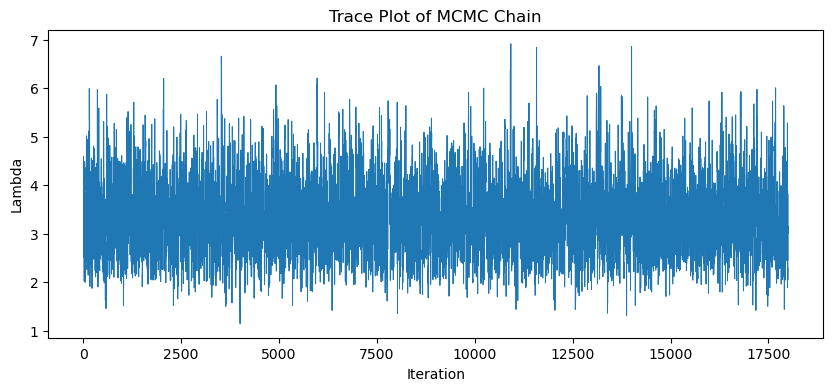

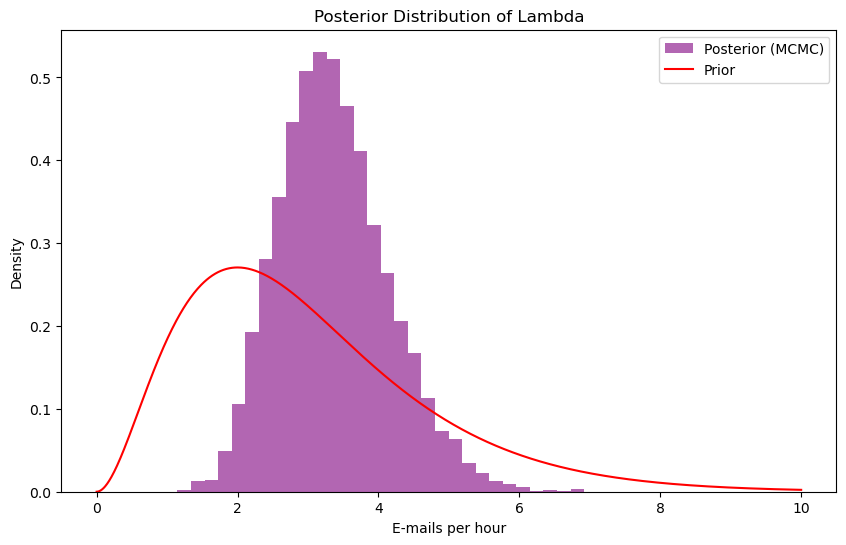

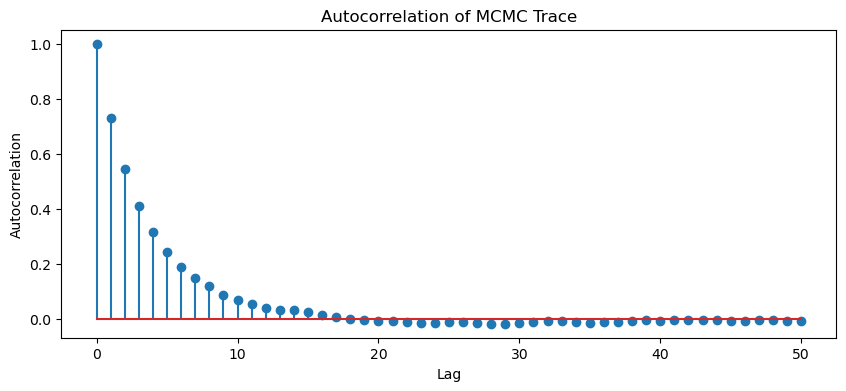

Posterior Mean: 3.36
95% Credible Interval: [2.02, 5.07]


In [44]:
import numpy as np
from scipy.stats import gamma, poisson
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import acf

# the observations of the number of e-mails received by HR each hour
data = [3, 4, 2, 5, 3]

# Initialize lambda as prior mean (alpha / beta for Gamma prior)
initial_lambda = 3  # since alpha=3, beta=1, mean=3/1=3
print("Initial Lambda:", initial_lambda)

# Gamma Prior
# Prior: Gamma(alpha=3, beta=1)
# scipy's gamma: a=alpha, scale=1/beta
rv = gamma(a=3, scale=1/1)
prior = lambda x: rv.pdf(x)


# implement: Likelihood function for Poisson model; likelihood(lam, data)
def likelihood(lam, data):
    """
    Compute the likelihood of the observed data given the Poisson rate parameter lambda.

    This function calculates the likelihood P(data | lambda) under the assumption 
    that the data are independent and identically distributed samples from a Poisson(lam) distribution.
    For numerical stability, it computes the sum of log-probabilities and then exponentiates.

    Parameters
    ----------
    lam : float or array-like
        The Poisson rate parameter (lambda). Can be a single value or an array for vectorized computation.
    data : array-like
        Observed data (counts), assumed to be non-negative integers.

    Returns
    -------
    float or np.ndarray
        The likelihood value(s) of the data given lambda.
    """
    # Return the likelihood by summing log probabilities for numerical stability
    return np.exp(np.sum(poisson.logpmf(data, lam)))


# implement: Posterior (up to a constant); posterior(lam, data)
def posterior(lam, data):
    """
    Compute the unnormalized posterior probability of lambda given the observed data.

    This function multiplies the prior probability of lambda by the likelihood of the data
    under a Poisson model, yielding the unnormalized posterior (since the normalizing constant is not computed).
    If lambda is non-positive, returns 0, as such values are not valid for the Poisson/Gamma distribution.

    Parameters
    ----------
    lam : float
        The Poisson rate parameter (lambda). Must be positive.
    data : array-like
        Observed data (counts), assumed to be non-negative integers.

    Returns
    -------
    float
        The unnormalized posterior probability of lambda given the data, or 0 if lambda is invalid.
    """
    # Avoid negative or zero lambda (invalid for Poisson/Gamma)
    if lam <= 0:
        return 0
    
    # Return the unnormalized posterior (prior * likelihood)
    return prior(lam) * likelihood(lam, data)


# implement: Metropolis-Hastings Algorithm; metropolis_hastings_normal(data, initial_lambda, sigma, iterations=10000, burn_in=1000). This function should return the chain samples and the number of samples accepted
def metropolis_hastings_normal(data, 
                               initial_lambda, 
                               sigma, 
                               iterations=10000, 
                               burn_in=1000):
    """
    Perform Metropolis-Hastings sampling for Poisson lambda using a normal proposal distribution.

    This function implements the Metropolis-Hastings algorithm to sample from the posterior distribution
    of the Poisson rate parameter (lambda), given observed count data and a prior (as defined in `posterior`).
    Proposals for lambda are drawn from a normal distribution centered at the current value with standard deviation `sigma`.

    Parameters
    ----------
    data : array-like
        Observed count data (non-negative integers).
    initial_lambda : float
        Initial value to start the Markov Chain (must be positive).
    sigma : float
        Standard deviation of the normal proposal distribution for lambda.
    iterations : int, optional
        Total number of iterations to run the sampler (default is 10,000).
    burn_in : int, optional
        Number of initial samples to discard (default is 1,000).

    Returns
    -------
    samples : np.ndarray
        Array of sampled lambda values after burn-in period.
    accepted : int
        The total number of proposals accepted during sampling.
    """
    # Initialize storage for samples
    samples = []

    # Start at the initial lambda value
    current = initial_lambda

    # Compute the current posterior
    current_post = posterior(current, data)

    # Track the number of accepted proposals
    accepted = 0

    # Iterate for the specified number of iterations
    for i in range(iterations):

        # Propose new lambda from normal distribution centered at current with sd=sigma
        proposal = np.random.normal(current, sigma)

        # Compute posterior at the proposal
        proposal_post = posterior(proposal, data)

        # Calculate acceptance probability (min of 1 and proposal/current posteriors)
        alpha = min(1, proposal_post / current_post) if current_post > 0 else 1

        # Accept or reject the proposal
        if np.random.rand() < alpha:
            current = proposal
            current_post = proposal_post
            accepted += 1

        # Store samples only after burn-in period
        if i >= burn_in:
            samples.append(current)

    # Return the chain and number of accepted proposals
    return np.array(samples), accepted


# Parameters
sigma = 1.0  # Standard deviation for Normal proposal
iterations = 20000
burn_in = 2000

# Run Metropolis-Hastings
chain, accepted = metropolis_hastings_normal(data, 
                                             initial_lambda, 
                                             sigma, 
                                             iterations, 
                                             burn_in)

# Print acceptance rate and calculate and display the acceptance rate of the sampler
acceptance_rate = accepted / iterations
print(f"Acceptance Rate: {acceptance_rate:.3f}")

# Plot the MCMC chain, plot the trace (value per iteration) of the MCMC chain to check stationarity and mixing
plt.figure(figsize=(10,4))
plt.plot(chain, lw=0.7)
plt.xlabel('Iteration')
plt.ylabel('Lambda')
plt.title('Trace Plot of MCMC Chain')
plt.show()

# Posterior distribution from MCMC samples
plt.figure(figsize=(10, 6))
plt.hist(chain, 
         bins=30, 
         density=True, 
         color='purple', 
         alpha=0.6, 
         label='Posterior (MCMC)')
x = np.linspace(0, 10, 1000)
plt.plot(x, 
         prior(x), 
         label='Prior', 
         color='red')
plt.xlabel("E-mails per hour")
plt.ylabel("Density")
plt.title("Posterior Distribution of Lambda")
plt.legend()
plt.show()

# Plot the autocorrelation with maximum number of lags 50; compute and plot autocorrelation function for the MCMC chain
lags = 50
acf_vals = acf(chain, nlags=lags)
plt.figure(figsize=(10, 4))
plt.stem(range(lags+1), acf_vals)
plt.xlabel('Lag')
plt.ylabel('Autocorrelation')
plt.title('Autocorrelation of MCMC Trace')
plt.show()

# Posterior mean and 95% credible interval
post_mean = np.mean(chain)
cred_interval = np.percentile(chain, [2.5, 97.5])
print(f"Posterior Mean: {post_mean:.2f}")
print(f"95% Credible Interval: [{cred_interval[0]:.2f}, {cred_interval[1]:.2f}]")

#### Implement the above cell again by changing the proposal function to a uniform distribution.

Initial Lambda: 3.4
Acceptance Rate: 0.620


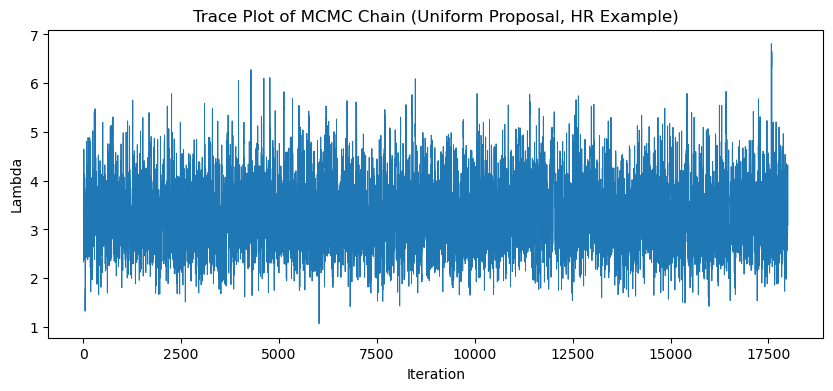

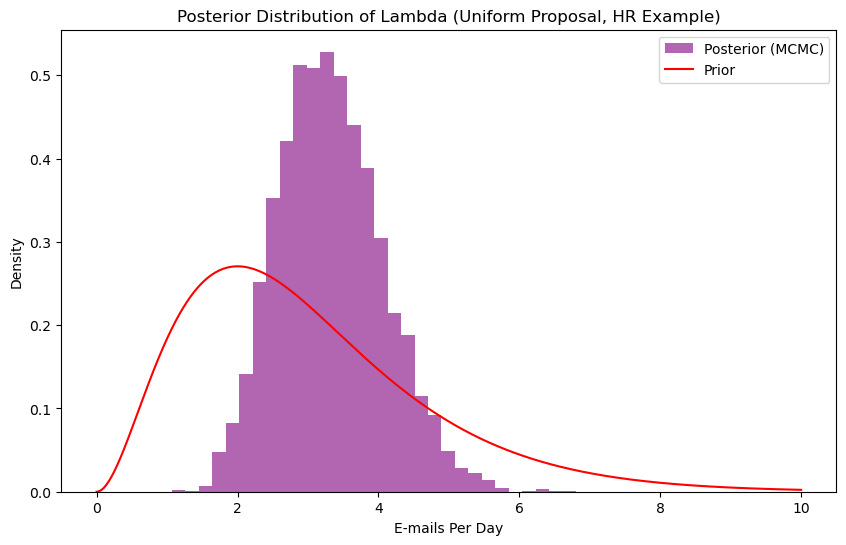

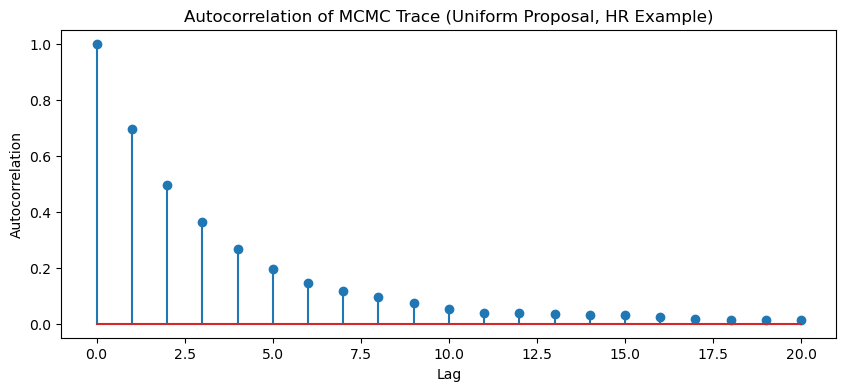

Posterior Mean: 3.32
95% Credible Interval: [2.01, 4.89]


In [45]:
import numpy as np
from scipy.stats import gamma, poisson
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import acf

# HR email example: observed number of emails per day
obs = [3, 
       4, 
       2, 
       5, 
       3]

# Gamma(3, 1) prior for lambda
prior_shape = 3
prior_rate = 1
prior = lambda x: gamma.pdf(x, 
                            a=prior_shape, 
                            scale=1/prior_rate)


# Likelihood function for Poisson model
def likelihood(lam, data):
    """
    Compute the likelihood of the observed data given the Poisson rate parameter lambda.

    This function calculates the likelihood P(data | lambda) under the assumption 
    that the data are independent and identically distributed samples from a Poisson(lam) distribution.
    For numerical stability, it computes the sum of log-probabilities and then exponentiates.

    Parameters
    ----------
    lam : float or array-like
        The Poisson rate parameter (lambda). Can be a single value or an array for vectorized computation.
    data : array-like
        Observed data (counts), assumed to be non-negative integers.

    Returns
    -------
    float or np.ndarray
        The likelihood value(s) of the data given lambda.
    """
    # Return the likelihood by summing log probabilities for numerical stability
    return np.exp(np.sum(poisson.logpmf(data, lam)))


# Posterior (unnormalized)
def posterior(lam, data):
    """
    Compute the unnormalized posterior probability of lambda given the observed data.

    This function multiplies the prior probability of lambda by the likelihood of the data
    under a Poisson model, yielding the unnormalized posterior (since the normalizing constant is not computed).
    If lambda is non-positive, returns 0, as such values are not valid for the Poisson/Gamma distribution.

    Parameters
    ----------
    lam : float
        The Poisson rate parameter (lambda). Must be positive.
    data : array-like
        Observed data (counts), assumed to be non-negative integers.

    Returns
    -------
    float
        The unnormalized posterior probability of lambda given the data, or 0 if lambda is invalid.
    """
    # Avoid negative or zero lambda (invalid for Poisson/Gamma)
    if lam <= 0:
        return 0

    # Return the unnormalized posterior (prior * likelihood)
    return prior(lam) * likelihood(lam, data)


# Metropolis-Hastings with uniform proposal
def metropolis_hastings_uniform(data, 
                               initial_lambda, 
                               delta, 
                               iterations=10000, 
                               burn_in=1000):
    """
    Perform Metropolis-Hastings sampling for Poisson lambda using a uniform proposal distribution.

    This function implements the Metropolis-Hastings algorithm to sample from the posterior distribution
    of the Poisson rate parameter (lambda), given observed count data and a prior (as defined in `posterior`).
    Proposals for lambda are drawn from a uniform distribution centered at the current value with width 2*delta.

    Parameters
    ----------
    data : array-like
        Observed count data (non-negative integers).
    initial_lambda : float
        Initial value to start the Markov Chain (must be positive).
    delta : float
        Half-width for the uniform proposal distribution for lambda.
    iterations : int, optional
        Total number of iterations to run the sampler (default is 10,000).
    burn_in : int, optional
        Number of initial samples to discard (default is 1,000).

    Returns
    -------
    samples : np.ndarray
        Array of sampled lambda values after burn-in period.
    accepted : int
        The total number of proposals accepted during sampling.
    """
    # Initialize storage for samples
    samples = []

    # Start at the initial lambda value
    current = initial_lambda

    # Compute the current posterior
    current_post = posterior(current, data)

    # Track the number of accepted proposals
    accepted = 0

    # Iterate for the specified number of iterations
    for i in range(iterations):

        # Propose new lambda from uniform distribution centered at current with width 2*delta
        proposal = np.random.uniform(current - delta, current + delta)

        # Compute posterior at the proposal
        proposal_post = posterior(proposal, data)

        # Calculate acceptance probability (min of 1 and proposal/current posteriors)
        alpha = min(1, proposal_post / current_post) if current_post > 0 else 1

        # Accept or reject the proposal
        if np.random.rand() < alpha:
            current = proposal
            current_post = proposal_post
            accepted += 1

        # Store samples only after burn-in period
        if i >= burn_in:
            samples.append(current)

    # Return the chain and number of accepted proposals
    return np.array(samples), accepted


# Parameters for uniform proposal
delta = 1.5  # Half-width for uniform proposal
iterations = 20000
burn_in = 2000

# Initialize lambda as the sample mean of observed counts
initial_lambda = np.mean(obs)
print('Initial Lambda:', initial_lambda)

# Run Metropolis-Hastings with uniform proposal
chain, accepted = metropolis_hastings_uniform(obs, 
                                              initial_lambda, 
                                              delta, 
                                              iterations, 
                                              burn_in)

# Print acceptance rate
acceptance_rate = accepted / iterations
print(f'Acceptance Rate: {acceptance_rate:.3f}')

# Plot the MCMC chain (trace plot)
plt.figure(figsize=(10,4))
plt.plot(chain, lw=0.7)
plt.xlabel('Iteration')
plt.ylabel('Lambda')
plt.title('Trace Plot of MCMC Chain (Uniform Proposal, HR Example)')
plt.show()

# Posterior distribution from MCMC samples
plt.figure(figsize=(10, 6))
plt.hist(chain, 
         bins=30, 
         density=True, 
         color='purple', 
         alpha=0.6, 
         label='Posterior (MCMC)')
x = np.linspace(0, 
                10, 
                1000)
plt.plot(x, 
         prior(x), 
         label='Prior', 
         color='red')
plt.xlabel('E-mails Per Day')
plt.ylabel('Density')
plt.title('Posterior Distribution of Lambda (Uniform Proposal, HR Example)')
plt.legend()
plt.show()

# Plot the autocorrelation function for the MCMC chain
lags = 20
acf_vals = acf(chain, nlags=lags)
plt.figure(figsize=(10, 4))
plt.stem(range(lags+1), acf_vals)
plt.xlabel('Lag')
plt.ylabel('Autocorrelation')
plt.title('Autocorrelation of MCMC Trace (Uniform Proposal, HR Example)')
plt.show()

# Posterior mean and 95% credible interval
post_mean = np.mean(chain)
cred_interval = np.percentile(chain, [2.5, 97.5])
print(f'Posterior Mean: {post_mean:.2f}')
print(f'95% Credible Interval: [{cred_interval[0]:.2f}, {cred_interval[1]:.2f}]')